# Análise exploratória: Bens Imóveis do Estado da Bahia

**Projeto:** Bootcamp Amazing Data Intelligence (MBA em Ciência e Engenharia de Dados, UNIESP)
**Fonte:** [dados.ba.gov.br, Bens Imóveis](https://dados.ba.gov.br/dataset/bens-imoveis) (SIMOV/SAEB), arquivo `imoveisproprios.json`

Este notebook investiga a base **depois da carga no Data Warehouse** (PostgreSQL) para:
1. entender a estrutura e o grão dos dados;
2. justificar cada decisão de tratamento feita no pipeline (ingestão em Python e ETL no Pentaho);
3. descrever distribuições, padrões e outliers;
4. definir as **métricas de negócio** que o dashboard do Power BI usa.

> Pré-requisito: banco no ar (`docker compose up -d`) e pipeline executado (`etl/executar_pipeline.ps1`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from sqlalchemy import create_engine

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = dict(l.split("=", 1) for l in (RAIZ / ".env").read_text(encoding="utf-8").splitlines()
           if "=" in l and not l.startswith("#"))
engine = create_engine(
    f"postgresql+psycopg2://{cfg['POSTGRES_USER']}:{cfg['POSTGRES_PASSWORD']}"
    f"@{cfg.get('POSTGRES_HOST', 'localhost')}:{cfg.get('POSTGRES_PORT', '5437')}/{cfg['POSTGRES_DB']}")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 4.5)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
bi = mtick.FuncFormatter(lambda v, _: f"R$ {v/1e9:,.1f} bi")

## 1. Estrutura e grão

O arquivo é um **array plano de objetos JSON** (sem aninhamento) com 8 campos. Antes de qualquer análise ele precisou ser
**reparado**, porque não é JSON válido. O relatório gerado por `ingestion/reparar_json.py`:

In [2]:
rel = json.loads((RAIZ / "data/processed/relatorio_reparo.json").read_text(encoding="utf-8"))
pd.Series(rel["correcoes"] | {"bom_removido": rel["bom_removido"], "registros": rel["registros"]}).to_frame("quantidade")

,quantidade
virgula_faltando_apos_exercicio,190544
virgula_sobrando_antes_de_chave,190544
valor_vazio_para_null,356
bom_removido,True
registros,190544


**Decisão:** corrigir só a sintaxe (BOM, vírgula faltando, vírgula sobrando, valor vazio → `null`) e gravar em arquivo novo.
O arquivo original fica intocado como camada *raw* (o script confere o hash SHA-256 antes e depois).

In [3]:
stg = pd.read_sql("SELECT * FROM stg.bens_imoveis", engine)
print(stg.shape)
stg.dtypes.to_frame("tipo")

(190544, 9)


,tipo
numero_patrimonio,int64
exercicio,int64
endereco,str
municipio,str
orgao_gestor,str
destino,str
valor,float64
dimensoes,float64
dt_carga,datetime64[us]


In [4]:
resumo = pd.DataFrame({
    "nulos": stg.isna().sum(),
    "distintos": stg.nunique(),
    "exemplo": stg.iloc[0],
})
resumo

,nulos,distintos,exemplo
numero_patrimonio,0,6809,1
exercicio,0,35,1996
endereco,19,6419,"CENTRO, RUA DO COLÉGIO, S/N"
municipio,0,417,ABAÍRA
orgao_gestor,0,33,SECRETARIA DA EDUCAÇÃO
destino,0,6,Não definido
valor,0,160822,"85,989.73"
dimensoes,356,6179,"1,637.27"
dt_carga,0,39,2026-10-17 17:49:03.048690


In [5]:
print("Duplicados (imóvel, exercício):", stg.duplicated(["numero_patrimonio", "exercicio"]).sum())
print("Imóveis distintos:", stg.numero_patrimonio.nunique())
print("Exercícios:", stg.exercicio.min(), "a", stg.exercicio.max())
stg.groupby("numero_patrimonio").exercicio.count().describe().to_frame("anos por imóvel")

Duplicados (imóvel, exercício): 0
Imóveis distintos: 6809
Exercícios: 1992 a 2026


,anos por imóvel
count,"6,809.00"
mean,27.98
std,8.48
min,1.00
25%,30.00
50%,31.00
75%,32.00
max,35.00


**Achado 1: o grão é imóvel × exercício.** O dicionário de dados descreve `Exercicio` como "ano de cadastro do imóvel", mas cada
imóvel aparece **uma vez por ano** (mediana de 31 anos por imóvel) com valores diferentes. Logo, `Exercicio` é o **ano de referência do
valor**. Isso define o modelo: a fato é um **snapshot periódico anual**, e o valor é **semiaditivo** (soma entre imóveis no mesmo ano,
nunca entre anos).

In [6]:
stg[stg.numero_patrimonio == 1][["exercicio", "valor", "dimensoes", "destino"]].head(8)

,exercicio,valor,dimensoes,destino
0,1996,"85,989.73","1,637.27",Não definido
1,1997,"85,425.22","1,637.27",Não definido
2,1998,"82,154.61","1,637.27",Não definido
3,1999,"78,884.00","1,637.27",Não definido
4,2000,"75,613.39","1,637.27",Não definido
5,2001,"72,333.82","1,637.27",Não definido
6,2002,"69,063.21","1,637.27",Não definido
7,2003,"65,792.60","1,637.27",Não definido


## 2. Qualidade dos dados e decisões de tratamento

### 2.1 Moeda anterior ao Real

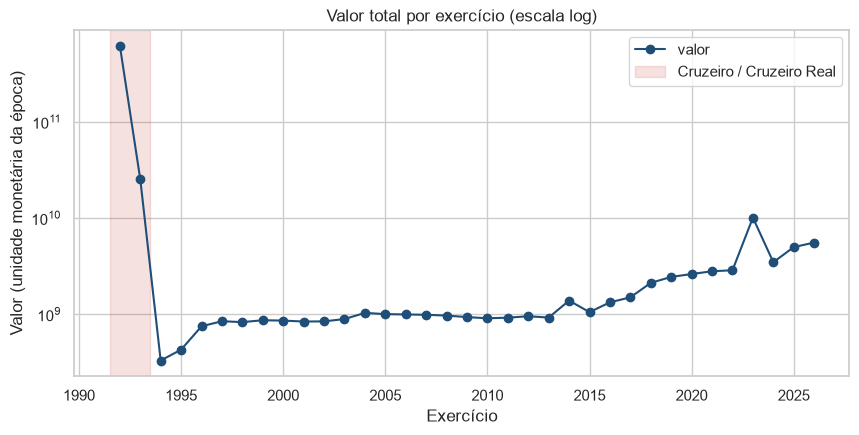

,valor_total
exercicio,
1992,"618,015,971,040.70"
1993,"25,317,947,318.91"
1994,"330,062,261.14"
1995,"427,768,691.35"
1996,"748,395,598.40"


In [7]:
tot = stg.groupby("exercicio").valor.sum()
fig, ax = plt.subplots()
tot.plot(ax=ax, marker="o", logy=True, color="#1f4e79")
ax.axvspan(1991.5, 1993.5, color="#c0392b", alpha=.15, label="Cruzeiro / Cruzeiro Real")
ax.set(title="Valor total por exercício (escala log)", xlabel="Exercício", ylabel="Valor (unidade monetária da época)")
ax.legend(); plt.show()
tot.loc[1992:1996].to_frame("valor_total")

**Achado 2:** 1992 soma 618 bilhões e 1993, 25 bilhões, contra 0,33 bilhão em 1994. São valores em **Cruzeiro e Cruzeiro Real**,
moedas anteriores ao Real (julho de 1994). **Decisão:** não apagar (é o dado da fonte) e marcar com `fl_moeda_pre_real` na `dim_tempo`;
todas as análises monetárias usam o período do Real.

### 2.2 Valor e área inválidos

In [8]:
q = pd.DataFrame({
    "valor nulo": [stg.valor.isna().sum()],
    "valor = 0": [(stg.valor == 0).sum()],
    "valor < 0": [(stg.valor < 0).sum()],
    "área nula": [stg.dimensoes.isna().sum()],
    "área = 0": [(stg.dimensoes == 0).sum()],
}, index=["linhas"]).T
q["% da base"] = 100 * q.linhas / len(stg)
q

,linhas,% da base
valor nulo,0,0.00
valor = 0,334,0.18
valor < 0,1,0.00
área nula,356,0.19
área = 0,5307,2.79


**Decisão:** manter as linhas e criar as flags `fl_valor_invalido` e `fl_area_invalida` na fato. Assim o imóvel continua contando
no total de imóveis, mas fica fora das médias e do valor por m². Não imputamos área nem valor: inventar um número de patrimônio público
seria pior do que declarar a lacuna.

### 2.3 Textos

In [9]:
raw = pd.read_csv(RAIZ / "data/processed/imoveis.csv", sep=";", dtype=str)
linhas = []
for col in ["Municipio", "OrgaoGestor", "Endereco"]:
    s = raw[col].fillna("")
    limpo = s.str.strip().str.replace(r"\s+", " ", regex=True).str.upper()
    linhas.append({"coluna": col, "espaço nas pontas": (s != s.str.strip()).sum(),
                   "espaço duplo": s.str.contains("  ").sum(),
                   "distintos (bruto)": s.nunique(), "distintos (padronizado)": limpo.nunique()})
pd.DataFrame(linhas).set_index("coluna")

,espaço nas pontas,espaço duplo,distintos (bruto),distintos (padronizado)
coluna,,,,
Municipio,26057,26057,417,417
OrgaoGestor,48,49,33,33
Endereco,9647,15870,11607,10915


`Municipio` vem com preenchimento de espaços até 30 caracteres (26 mil linhas) e há órgão com espaço duplo
("DESENVOLVIMENTO  URBANO"). **Decisão:** no Pentaho (`01_stg_bens_imoveis.ktr`) aplicar *trim*, caixa alta e remoção de espaços
repetidos antes da staging; sem isso, o mesmo município viraria duas linhas na dimensão.

### 2.4 Atributos que mudam ao longo do tempo

In [10]:
mud = {c: int((stg.groupby("numero_patrimonio")[c].nunique() > 1).sum())
       for c in ["orgao_gestor", "destino", "municipio", "dimensoes", "endereco"]}
pd.Series(mud).to_frame("imóveis com mais de um valor")

,imóveis com mais de um valor
orgao_gestor,571
destino,464
municipio,4
dimensoes,269
endereco,683


**Decisão de modelagem:** 571 imóveis trocaram de órgão gestor e 464 de destino. Por isso órgão, destino e município ficam
**ligados na fato por exercício**, e não fixos na `dim_imovel`: cada ano guarda a situação daquele ano (o mesmo efeito de uma SCD tipo 2,
sem versionar a dimensão). A `dim_imovel` guarda só os atributos mais recentes (endereço e área, SCD tipo 1).

## 3. Distribuições (exercício mais recente)

In [11]:
fato = pd.read_sql('''
    SELECT f.*, i.numero_patrimonio, t.ano, t.fl_ultimo_ano, t.fl_moeda_pre_real, m.municipio, m.fl_capital, m.fl_regiao_metropolitana,
           o.orgao_gestor, o.area_governo, d.destino, d.grupo_destino
    FROM dw.fato_patrimonio_anual f
    JOIN dw.dim_imovel i USING (sk_imovel) JOIN dw.dim_tempo t USING (sk_tempo) JOIN dw.dim_municipio m USING (sk_municipio)
    JOIN dw.dim_orgao o USING (sk_orgao) JOIN dw.dim_destino d USING (sk_destino)''', engine)
ult = fato[fato.fl_ultimo_ano].copy()
ANO = int(ult.ano.iloc[0])
print(f"Exercício {ANO}: {len(ult):,} imóveis, valor total R$ {ult.valor.sum()/1e9:,.2f} bi")
ult.valor.describe(percentiles=[.25, .5, .75, .9, .99]).to_frame("valor (R$)")

Exercício 2026: 6,477 imóveis, valor total R$ 5.54 bi


,valor (R$)
count,"6,477.00"
mean,"855,981.90"
std,"7,721,296.20"
min,0.00
25%,"1,008.38"
50%,"4,600.87"
75%,"21,826.85"
90%,"186,789.43"
99%,"21,912,451.48"
max,"357,250,000.00"


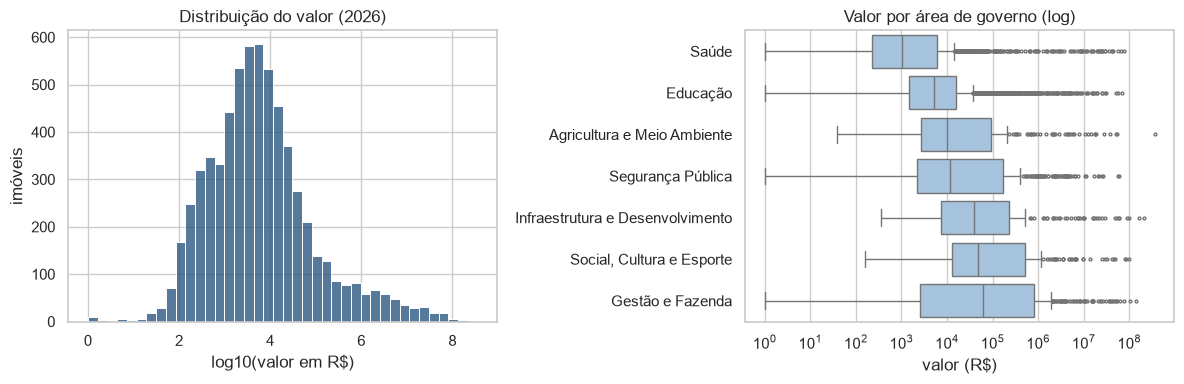

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
v = ult.loc[ult.valor > 0, "valor"]
sns.histplot(np.log10(v), bins=40, ax=axes[0], color="#1f4e79")
axes[0].set(title=f"Distribuição do valor ({ANO})", xlabel="log10(valor em R$)", ylabel="imóveis")
ordem = ult.groupby("area_governo").valor.median().sort_values().index
sns.boxplot(data=ult[ult.valor > 0], y="area_governo", x="valor", order=ordem, ax=axes[1], color="#9dc3e6", fliersize=2)
axes[1].set(xscale="log", title="Valor por área de governo (log)", xlabel="valor (R$)", ylabel="")
plt.tight_layout(); plt.show()

A distribuição do valor é **fortemente assimétrica** (mediana na casa das dezenas de milhares, cauda de centenas de milhões).
Por isso o dashboard usa **mediana** e **participação %** além da soma, e os gráficos de valor usam escala log ou ranking.

## 4. Outliers: valor por m²

In [13]:
ok = ult[(~ult.fl_area_invalida) & (~ult.fl_valor_invalido)].copy()
ok["valor_m2"] = ok.valor / ok.area_m2
lg = np.log10(ok.valor_m2)
q1, q3 = lg.quantile([.25, .75]); iqr = q3 - q1
ok["outlier"] = (lg < q1 - 1.5 * iqr) | (lg > q3 + 1.5 * iqr)
print(f"Imóveis com área e valor válidos: {len(ok):,}; outliers (IQR em log): {ok.outlier.sum():,} "
      f"({100*ok.outlier.mean():.1f}%)")
print(f"Mediana do valor/m²: R$ {ok.valor_m2.median():,.2f}")
ok.nlargest(8, "valor_m2")[["numero_patrimonio", "municipio", "orgao_gestor", "area_m2", "valor", "valor_m2"]]

Imóveis com área e valor válidos: 6,081; outliers (IQR em log): 382 (6.3%)
Mediana do valor/m²: R$ 3.48


,numero_patrimonio,municipio,orgao_gestor,area_m2,valor,valor_m2
122942,4262,SALVADOR,SECRETARIA DA CULTURA,873.56,"80,700,000.00","92,380.60"
126095,4365,SALVADOR,SECRETARIA DA CULTURA,177.69,"13,399,014.79","75,406.69"
130068,4487,SALVADOR,SECRETARIA DE DESENVOLVIMENTO ECONÔMICO,"1,819.69","47,950,760.27","26,351.06"
190536,8451,SALVADOR,SECRETARIA DA SAÚDE,"1,152.00","29,553,000.00","25,653.65"
122032,4234,SALVADOR,SECRETARIA DE TURISMO,"4,126.89","99,481,314.26","24,105.64"
126061,4364,SALVADOR,SECRETARIA DE JUSTICA E DIREITOS HUMANOS - SJDH,494.71,"5,418,843.09","10,953.58"
32829,1152,CÍCERO DANTAS,POLÍCIA CIVIL DA BAHIA,99.75,"1,047,603.86","10,502.29"
123149,4270,SALVADOR,SECRETARIA DA SEGURANÇA PÚBLICA,"2,780.85","26,419,342.80","9,500.46"


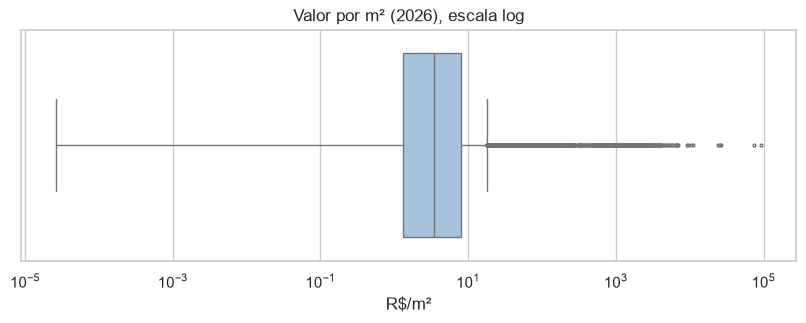

In [14]:
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=ok.valor_m2, ax=ax, color="#9dc3e6", fliersize=2)
ax.set(xscale="log", title=f"Valor por m² ({ANO}), escala log", xlabel="R$/m²"); plt.show()

**Achado:** a mediana de poucos reais por m² mostra que `valor` é **valor contábil depreciado** (o imóvel perde cerca de 5% ao ano,
veja a seção 5.1), e não valor de mercado. O dashboard deixa isso explícito para não induzir o público a erro.

**Decisão:** outliers de valor/m² **não são removidos** (podem ser terrenos pequenos em área nobre ou glebas rurais enormes); ficam
visíveis numa tabela de auditoria no dashboard. Para comparações entre municípios usamos o valor/m² agregado
(`soma do valor / soma da área`), que é robusto a um imóvel extremo.

## 5. Padrões de negócio

### 5.1 Evolução do patrimônio (período do Real)

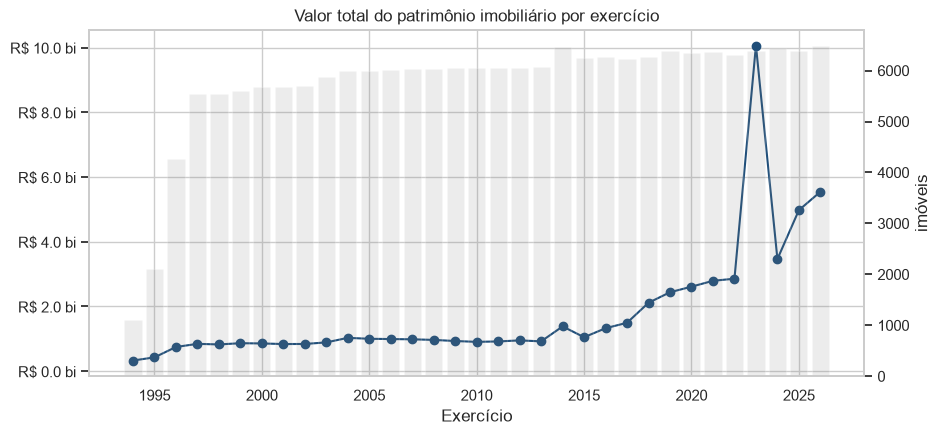

,valor,imoveis,var_%
ano,,,
2019,"2,439,894,182.07",6384,15.37
2020,"2,612,345,881.83",6338,7.07
2021,"2,792,732,848.54",6371,6.91
2022,"2,858,568,140.46",6300,2.36
2023,"10,063,886,497.39",6384,252.06
2024,"3,464,632,595.05",6435,-65.57
2025,"4,976,818,902.19",6389,43.65
2026,"5,544,194,785.17",6477,11.40


In [15]:
serie = fato[~fato.fl_moeda_pre_real].groupby("ano").agg(valor=("valor", "sum"), imoveis=("sk_imovel", "count"))
serie["var_%"] = 100 * serie.valor.pct_change()
fig, ax = plt.subplots()
ax.plot(serie.index, serie.valor, marker="o", color="#1f4e79")
ax.yaxis.set_major_formatter(bi); ax.set(title="Valor total do patrimônio imobiliário por exercício", xlabel="Exercício")
ax2 = ax.twinx(); ax2.bar(serie.index, serie.imoveis, alpha=.15, color="gray"); ax2.set_ylabel("imóveis"); ax2.grid(False)
plt.show()
serie.tail(8)

In [16]:
s = fato[~fato.fl_moeda_pre_real].sort_values(["sk_imovel", "ano"])
s["var"] = s.groupby("sk_imovel").valor.pct_change()
s = s.replace([np.inf, -np.inf], np.nan).dropna(subset=["var"])
print(f"Variação anual mediana do valor de um mesmo imóvel: {100*s['var'].median():.1f}%")
print(f"Pares ano a ano com aumento de valor: {100*(s['var'] > 0).mean():.1f}%")

Variação anual mediana do valor de um mesmo imóvel: -4.9%
Pares ano a ano com aumento de valor: 2.0%


**Achado 3:** o valor de cada imóvel cai cerca de **5% ao ano** (depreciação contábil), mas o total do Estado **dobrou de 2020 para
2026** (R$ 2,6 bi → R$ 5,5 bi). O salto vem de **reavaliações e novos imóveis incorporados**, e não da valorização natural. É uma
pergunta para a SAEB e um bom ponto de storytelling.

### 5.2 Concentração geográfica

In [17]:
ult["regiao"] = np.select([ult.fl_capital, ult.fl_regiao_metropolitana], ["Salvador", "RMS (sem Salvador)"], "Interior")
reg = ult.groupby("regiao").agg(imoveis=("sk_imovel", "count"), valor=("valor", "sum"))
reg["% imóveis"] = 100 * reg.imoveis / reg.imoveis.sum(); reg["% valor"] = 100 * reg.valor / reg.valor.sum()
reg.sort_values("valor", ascending=False)

,imoveis,valor,% imóveis,% valor
regiao,,,,
Salvador,719,"3,702,171,911.16",11.10,66.78
Interior,5573,"1,547,282,749.63",86.04,27.91
RMS (sem Salvador),185,"294,740,124.38",2.86,5.32


**Achado 4:** Salvador tem **11% dos imóveis e 67% do valor**. O interior tem 86% dos imóveis (escolas e postos de saúde de menor valor).

### 5.3 Destinação

In [18]:
dest = ult.groupby(["grupo_destino", "destino"]).agg(imoveis=("sk_imovel", "count"), valor=("valor", "sum"))
dest["% imóveis"] = 100 * dest.imoveis / dest.imoveis.sum(); dest["% valor"] = 100 * dest.valor / dest.valor.sum()
dest.sort_values("imoveis", ascending=False)

imoveis            valor  % imóveis  \
grupo_destino       destino                                                     
Sem destinação      Não definido             5900 2,821,409,736.51      91.09   
Em uso              Uso                       443 2,058,169,021.68       6.84   
Alienação e outorga Alienação                  92    98,999,356.68       1.42   
                    PROJETO DE ALIENAÇÃO       21   444,423,766.91       0.32   
                    OUTORGADA À EMPRESA        18   119,707,056.88       0.28   
                    ARREMATADO/LEILÃO           3     1,485,846.51       0.05   

                                          % valor  
grupo_destino       destino                        
Sem destinação      Não definido            50.89  
Em uso              Uso                     37.12  
Alienação e outorga Alienação                1.79  
                    PROJETO DE ALIENAÇÃO     8.02  
                    OUTORGADA À EMPRESA      2.16  
                    ARREMATADO/LEILÃO        0.03

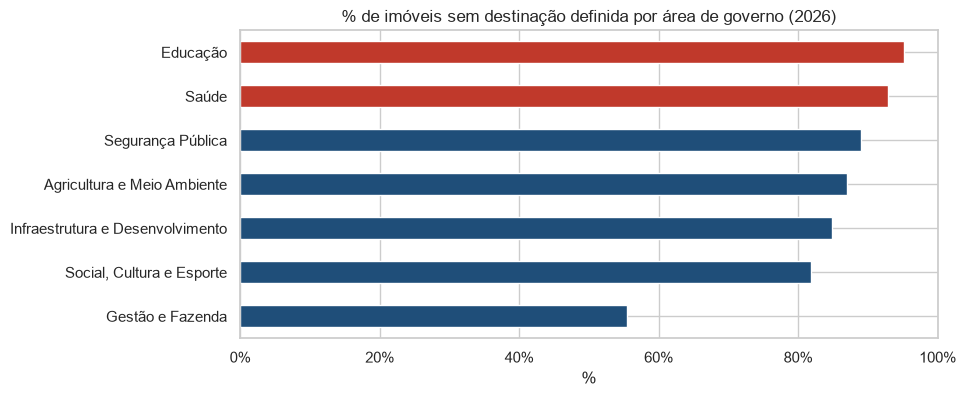

In [19]:
p = (ult.assign(sem_destino=ult.grupo_destino.eq("Sem destinação"))
        .groupby("area_governo").sem_destino.mean().sort_values() * 100)
ax = p.plot.barh(color=["#c0392b" if v > 90 else "#1f4e79" for v in p], figsize=(9, 4))
ax.set(title=f"% de imóveis sem destinação definida por área de governo ({ANO})", xlabel="%", ylabel="")
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); plt.show()

**Achado 5 (central para o storytelling):** **91% dos imóveis (5.900) estão com destino "Não definido"**, somando R$ 2,8 bi. Na Educação
são 95% e na Saúde, 93%. Pode ser falta de registro (o imóvel é usado, mas o cadastro não diz) ou ociosidade de fato; nos dois casos é um
problema de **governança do patrimônio**. Já os imóveis em alienação, projeto de alienação, leilão ou outorga somam **≈ R$ 0,66 bi**:
patrimônio com potencial de receita.

## 6. Métricas de negócio para o dashboard

| Métrica | Definição | Por quê |
|---|---|---|
| **Valor do patrimônio** | Soma de `valor` no **último exercício** do filtro | Valor é semiaditivo: somar anos contaria o mesmo imóvel várias vezes |
| **Imóveis** | Contagem distinta de imóveis no último exercício | Mesmo motivo |
| **Valor mediano** | Mediana de `valor` (valores válidos) | Distribuição muito assimétrica |
| **% sem destinação** | Imóveis com grupo "Sem destinação" / imóveis | Indicador de governança (achado 5) |
| **Valor com potencial de receita** | Soma do valor no grupo "Alienação e outorga" | Pergunta de negócio 4 |
| **Valor por m²** | Soma do valor / soma da área (só registros válidos) | Robusto a outliers |
| **Variação % anual** | Valor do ano / valor do ano anterior − 1 | Evolução (achado 3) |
| **% cadastro completo** | Imóveis com área e valor válidos / imóveis | Qualidade do cadastro |

As medidas DAX correspondentes estão em `dashboard/medidas_dax.md`.

## 7. Conclusões

1. A base atende a um projeto de BI completo: 190.544 linhas, 35 exercícios, 4 eixos de análise e medidas numéricas.
2. Os principais tratamentos são reparo de sintaxe, padronização de textos, flags de qualidade e separação da moeda pré-Real; todos
   preservam o dado original.
3. A história para o público não técnico: **"A Bahia tem R$ 5,5 bi em imóveis próprios, dois terços em Salvador, e 9 em cada 10 não têm
   destinação registrada. Saber o que está ocioso é o primeiro passo para usar melhor ou gerar receita."**